In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [ ]:
df=pd.read_excel('/content/dữ liệu sau khi xử lý.xlsx')
print(df.shape)
print(df.head())

(2745, 11)
         Ngay  GiaDieuChinh  GiaDongCua  ThayDoi (%)  ThayDoi      ThayDoi.1  \
0  31/12/2025          38.9        38.9        -1.27     -0.5  -0.5(-1.27 %)   
1  30/12/2025          39.4        39.4         1.55      0.6    0.6(1.55 %)   
2  29/12/2025          38.8        38.8         0.00      0.0      0(0.00 %)   
3  26/12/2025          38.8        38.8         0.00      0.0      0(0.00 %)   
4  25/12/2025          38.8        38.8         1.04      0.4    0.4(1.04 %)   

   KhoiLuongKhopLenh  GiaTriKhopLenh  GiaMoCua  GiaCaoNhat  GiaThapNhat  
0            1630700     63833960000     39.50       39.55        38.90  
1            5379000    212100540000     38.80       39.85        38.65  
2            1644300     63737355000     38.80       38.90        38.60  
3            2657200    101999250000     38.45       38.80        38.00  
4            3728800    144065975000     38.40       38.95        38.35  


In [ ]:
# Ensure 'Ngay' is a column before processing
if 'Ngay' not in df.columns and df.index.name == 'Ngay':
    df.reset_index(inplace=True)

# Convert 'Ngay' column to datetime
df['Ngay'] = pd.to_datetime(df['Ngay'], format='%d/%m/%Y')

# Set 'Ngay' as the index
df.set_index('Ngay', inplace=True)

# Sort the DataFrame by its new datetime index in ascending order
# This is crucial for correct time series processing
df.sort_index(ascending=True, inplace=True)

# Select the target variable, 'GiaDongCua'
series = df['GiaDongCua']

# Display the first few rows of the processed series
print(series.head())
print(f"\nShape of the series: {series.shape}")

Ngay
2015-01-05    12.9
2015-01-06    13.2
2015-01-07    13.6
2015-01-08    13.6
2015-01-09    14.5
Name: GiaDongCua, dtype: float64

Shape of the series: (2745,)


In [ ]:
train_size = int(len(series) * 0.8)
train_series, test_series = series[0:train_size], series[train_size:]

print(f"Training data points: {len(train_series)}")
print(f"Testing data points: {len(test_series)}")

Training data points: 2196
Testing data points: 549


### Kiểm định tính dừng

Trước khi áp dụng mô hình ARIMA, cần kiểm tra xem chuỗi thời gian có tính dừng (stationarity) hay không. Một chuỗi được xem là dừng khi giá trị trung bình, phương sai và cấu trúc tự tương quan không thay đổi theo thời gian. Để kiểm tra điều này, ta sử dụng kiểm định Augmented Dickey-Fuller (ADF).

Nếu giá trị p-value lớn hơn mức ý nghĩa đã chọn (ví dụ: 0,05), thì chuỗi được xem là không dừng (non-stationary) và cần thực hiện sai phân (differencing) để đưa chuỗi về trạng thái dừng trước khi xây dựng mô hình ARIMA.

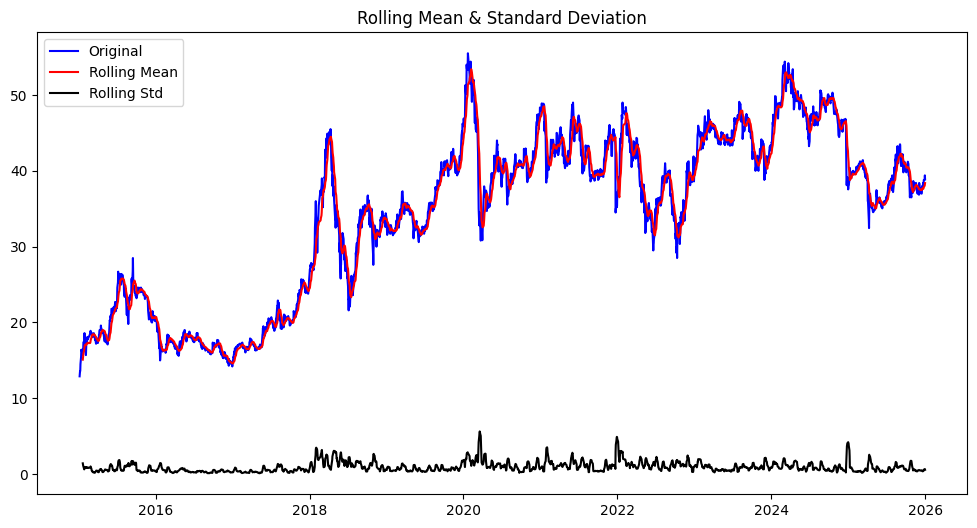

Results of Dickey-Fuller Test:
Test Statistic                   -2.446654
p-value                           0.128999
#Lags Used                        0.000000
Number of Observations Used    2744.000000
Critical Value (1%)              -3.432735
Critical Value (5%)              -2.862594
Critical Value (10%)             -2.567331
dtype: float64


In [ ]:
from statsmodels.tsa.stattools import adfuller

def check_stationarity(timeseries):
    # Determing rolling statistics
    rolmean = timeseries.rolling(window=12).mean()
    rolstd = timeseries.rolling(window=12).std()

    # Plot rolling statistics:
    plt.figure(figsize=(12, 6))
    plt.plot(timeseries, color='blue', label='Original')
    plt.plot(rolmean, color='red', label='Rolling Mean')
    plt.plot(rolstd, color='black', label='Rolling Std')
    plt.legend(loc='best')
    plt.title('Rolling Mean & Standard Deviation')
    plt.show(block=False)

    # Perform Dickey-Fuller test:
    print('Results of Dickey-Fuller Test:')
    dftest = adfuller(timeseries, autolag='AIC')
    dfoutput = pd.Series(dftest[0:4], index=['Test Statistic', 'p-value', '#Lags Used', 'Number of Observations Used'])
    for key, value in dftest[4].items():
        dfoutput['Critical Value (%s)' % key] = value
    print(dfoutput)

check_stationarity(series)

### Lấy sai phân

Do chuỗi gốc không có tính dừng (p-value > 0,05), chúng ta cần thực hiện **sai phân (differencing)**. Sai phân bậc một được thực hiện bằng cách lấy **giá trị hiện tại trừ đi giá trị quan sát liền trước đó**. Sau khi sai phân, chuỗi mới sẽ được kiểm tra lại tính dừng bằng kiểm định ADF.

Nếu **p-value của chuỗi sau sai phân nhỏ hơn 0,05**, có thể kết luận rằng chuỗi đã trở nên **dừng** và phù hợp để xây dựng mô hình ARIMA.


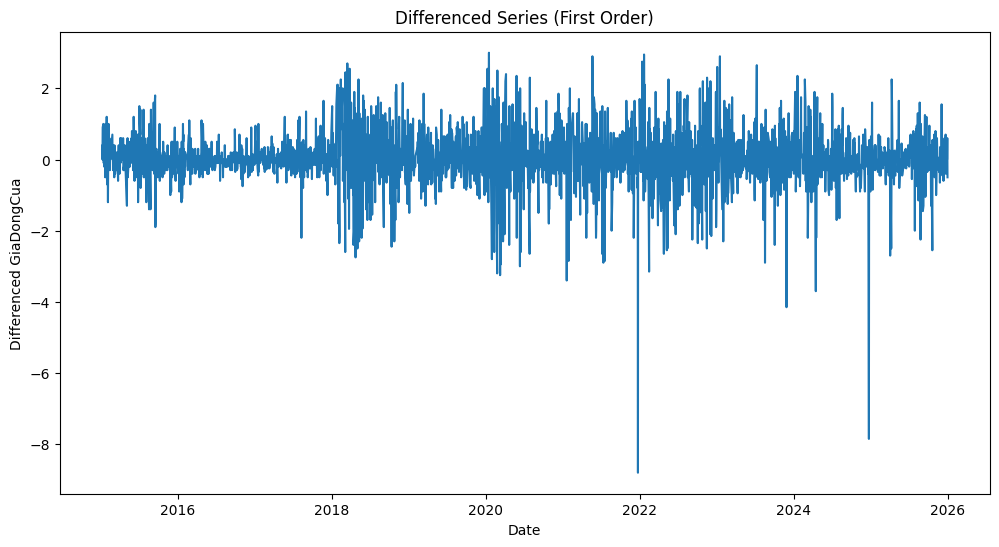


Checking stationarity of differenced series:


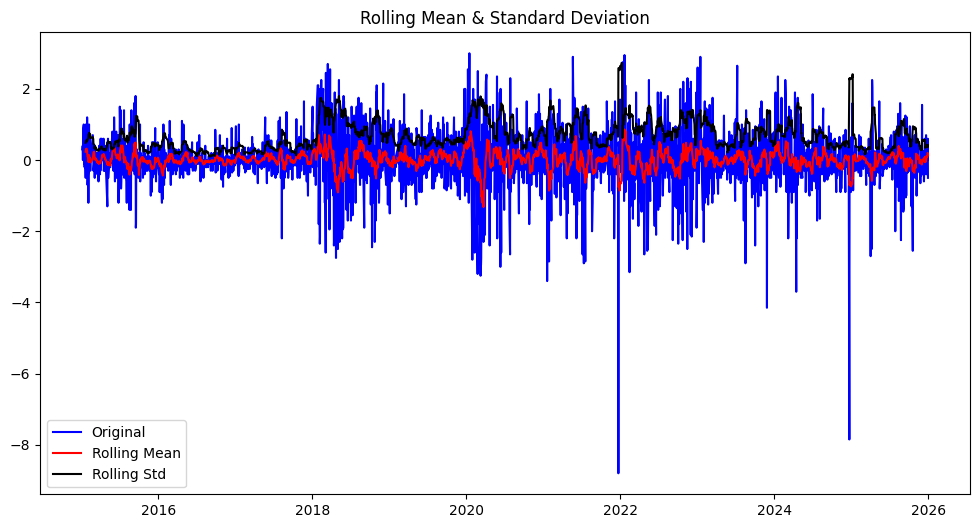

Results of Dickey-Fuller Test:
Test Statistic                  -52.753894
p-value                           0.000000
#Lags Used                        0.000000
Number of Observations Used    2743.000000
Critical Value (1%)              -3.432736
Critical Value (5%)              -2.862594
Critical Value (10%)             -2.567331
dtype: float64


In [ ]:
# Apply first-order differencing
diff_series = series.diff().dropna()

# Plot the differenced series
plt.figure(figsize=(12, 6))
plt.plot(diff_series)
plt.title('Differenced Series (First Order)')
plt.xlabel('Date')
plt.ylabel('Differenced GiaDongCua')
plt.show()

# Check stationarity of the differenced series
print('\nChecking stationarity of differenced series:')
check_stationarity(diff_series)

### Xác định các tham số ARIMA (p, d, q)

Sau khi chuỗi đã đạt được **tính dừng**, bước tiếp theo là xác định các tham số **p** (bậc tự hồi quy) và **q** (bậc trung bình trượt) cho mô hình ARIMA. Tham số **d** (bậc sai phân) đã được xác định là **1** từ bước trước. Để lựa chọn các giá trị phù hợp cho **p** và **q**, ta sử dụng đồ thị **ACF (Autocorrelation Function)** và **PACF (Partial Autocorrelation Function)**.

* **Đồ thị ACF**: Hỗ trợ xác định tham số **q**, tức bậc của thành phần **Moving Average (MA)**. Giá trị q thường được chọn dựa trên số độ trễ (lag) mà hệ số tự tương quan vẫn còn có ý nghĩa thống kê trước khi giảm dần về 0.
* **Đồ thị PACF**: Hỗ trợ xác định tham số **p**, tức bậc của thành phần **AutoRegressive (AR)**. Giá trị p thường được xác định dựa trên số độ trễ mà hệ số tự tương quan riêng phần còn có ý nghĩa thống kê trước khi bị cắt cụt.

Dựa vào việc phân tích hai đồ thị này, có thể đề xuất một số mô hình ARIMA ứng viên trước khi lựa chọn mô hình tối ưu thông qua các tiêu chí đánh giá như **AIC**, **BIC** hoặc kiểm định phần dư.


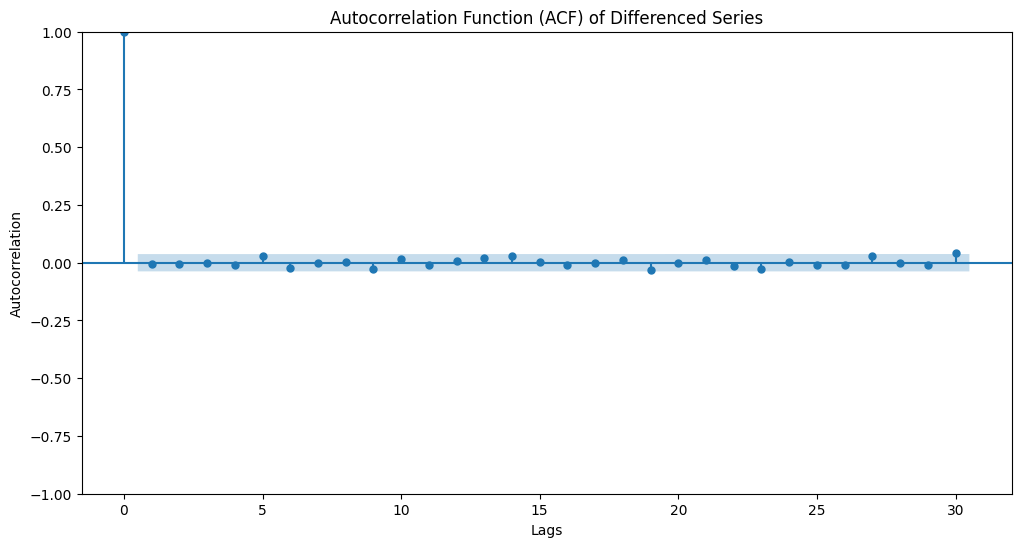

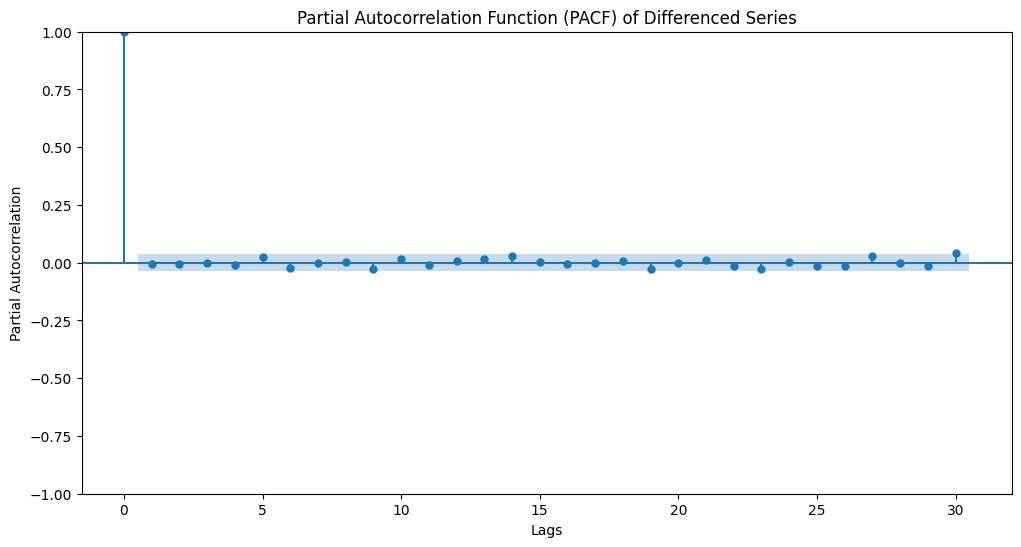

In [ ]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Plot ACF
plt.figure(figsize=(12, 6))
plot_acf(diff_series, lags=30, ax=plt.gca())
plt.title('Autocorrelation Function (ACF) of Differenced Series')
plt.xlabel('Lags')
plt.ylabel('Autocorrelation')
plt.show()

# Plot PACF
plt.figure(figsize=(12, 6))
plot_pacf(diff_series, lags=30, ax=plt.gca())
plt.title('Partial Autocorrelation Function (PACF) of Differenced Series')
plt.xlabel('Lags')
plt.ylabel('Partial Autocorrelation')
plt.show()

### Xây dựng và huấn luyện mô hình ARIMA

Dựa trên kết quả phân tích từ các đồ thị **ACF** và **PACF**, chúng ta lựa chọn các giá trị tối ưu cho tham số **p** và **q** của mô hình ARIMA. Tham số **d** đã được xác định bằng **1** do dữ liệu đã được thực hiện sai phân bậc một để đạt tính dừng.

Sau khi xác định bộ tham số **(p, d, q)** phù hợp, mô hình **ARIMA** sẽ được xây dựng và huấn luyện trên tập dữ liệu huấn luyện (*training set*). Quá trình này cho phép mô hình học được các đặc điểm và cấu trúc phụ thuộc theo thời gian của chuỗi dữ liệu, từ đó tạo cơ sở cho việc dự báo các giá trị trong tương lai. Các tham số của mô hình sẽ được ước lượng bằng phương pháp cực đại hóa khả năng xảy ra (*Maximum Likelihood Estimation*), nhằm đảm bảo mô hình phù hợp nhất với dữ liệu quan sát.


In [ ]:
from statsmodels.stats.diagnostic import acorr_ljungbox

model_dict = {}

for p in list_p:
    for d in list_d:
        for q in list_q:
            try:
                model_fit = ARIMA(train_series, order=(p,d,q)).fit()

                # Kiểm định Ljung-Box lag 10
                lb_p = acorr_ljungbox(model_fit.resid, lags=[10],
                                      return_df=True)['lb_pvalue'].values[0]

                # Chỉ lưu mô hình có phần dư sạch
                if lb_p > 0.05:
                    model_dict[(p,d,q)] = {
                        'aic': model_fit.aic,
                        'bic': model_fit.bic,
                        'lb_p': lb_p
                    }
                    print(f'✅ ARIMA({p},{d},{q}) - AIC:{model_fit.aic:.1f} '
                          f'BIC:{model_fit.bic:.1f} LjungBox_p:{lb_p:.3f}')
                else:
                    print(f'❌ ARIMA({p},{d},{q}) - phần dư còn tự tương quan '
                          f'(LjungBox_p={lb_p:.4f})')
            except Exception as e:
                pass

# Chọn mô hình tốt nhất trong các mô hình đã qua kiểm định
if model_dict:
    best = min(model_dict, key=lambda x: model_dict[x]['bic'])
    print(f"\n✅ Mô hình tốt nhất (BIC thấp nhất + phần dư sạch):")
    print(f"   ARIMA{best} — AIC={model_dict[best]['aic']:.3f}, "
          f"BIC={model_dict[best]['bic']:.3f}, "
          f"LjungBox_p={model_dict[best]['lb_p']:.3f}")
else:
    print("\nKhông có mô hình nào thỏa mãn")
    best = (1, 1, 1)

p, d, q = best

✅ ARIMA(0,1,0) - AIC:5299.8 BIC:5305.5 LjungBox_p:0.585
✅ ARIMA(0,1,1) - AIC:5301.4 BIC:5312.8 LjungBox_p:0.617
✅ ARIMA(0,1,2) - AIC:5303.4 BIC:5320.5 LjungBox_p:0.627
✅ ARIMA(0,1,3) - AIC:5305.2 BIC:5328.0 LjungBox_p:0.639
✅ ARIMA(0,1,4) - AIC:5306.9 BIC:5335.4 LjungBox_p:0.689
✅ ARIMA(0,1,5) - AIC:5307.5 BIC:5341.7 LjungBox_p:0.857
✅ ARIMA(0,1,6) - AIC:5308.5 BIC:5348.4 LjungBox_p:0.876
✅ ARIMA(0,1,7) - AIC:5310.5 BIC:5356.1 LjungBox_p:0.875
✅ ARIMA(1,1,0) - AIC:5301.4 BIC:5312.8 LjungBox_p:0.618
✅ ARIMA(1,1,1) - AIC:5303.4 BIC:5320.5 LjungBox_p:0.622
✅ ARIMA(1,1,2) - AIC:5305.4 BIC:5328.2 LjungBox_p:0.627
✅ ARIMA(1,1,3) - AIC:5307.3 BIC:5335.8 LjungBox_p:0.634
✅ ARIMA(1,1,4) - AIC:5308.6 BIC:5342.7 LjungBox_p:0.748
✅ ARIMA(1,1,5) - AIC:5308.9 BIC:5348.8 LjungBox_p:0.877
✅ ARIMA(1,1,6) - AIC:5310.5 BIC:5356.1 LjungBox_p:0.875
✅ ARIMA(1,1,7) - AIC:5309.3 BIC:5360.6 LjungBox_p:0.966
✅ ARIMA(2,1,0) - AIC:5303.4 BIC:5320.5 LjungBox_p:0.627
✅ ARIMA(2,1,1) - AIC:5304.9 BIC:5327.7 LjungBox_

In [ ]:
from statsmodels.tsa.arima.model import ARIMA

# Define the ARIMA order as (0, 1, 0)
p, d, q = (0, 1, 0)

# Fit the ARIMA model
arima_model = ARIMA(train_series, order=(p, d, q))
arima_model_fit = arima_model.fit()

# Print the model summary
print(arima_model_fit.summary())

                               SARIMAX Results                                
Dep. Variable:             GiaDongCua   No. Observations:                 2196
Model:                 ARIMA(0, 1, 0)   Log Likelihood               -2648.916
Date:                Fri, 19 Jun 2026   AIC                           5299.833
Time:                        07:07:09   BIC                           5305.527
Sample:                             0   HQIC                          5301.914
                               - 2196                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
sigma2         0.6542      0.009     75.450      0.000       0.637       0.671
Ljung-Box (L1) (Q):                   0.43   Jarque-Bera (JB):              6740.13
Prob(Q):                              0.51   Pr

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)


### Thực hiện dự báo và Đánh giá (bao gồm R-squared)

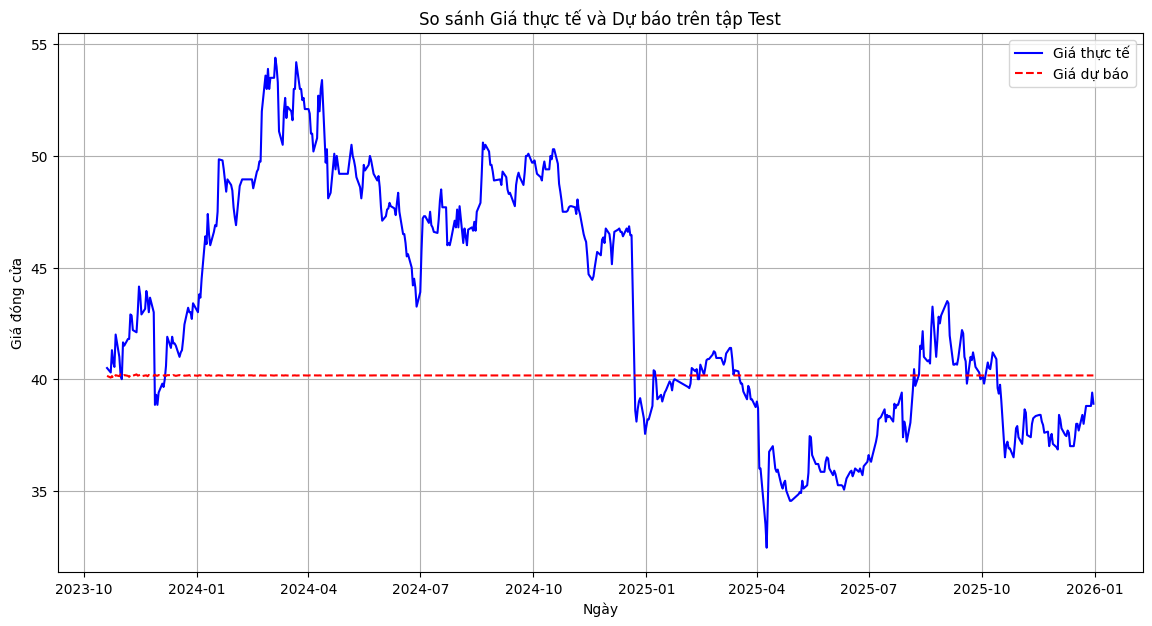

In [ ]:
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
import numpy as np

# 1. Dự báo trên tập test (chuỗi gốc)
# Prediction indices relative to the original full series
start_pred_idx = len(train_series)
end_pred_idx = len(series) - 1

# Get predictions in the original scale (levels) directly
predictions_original = model_fit.predict(start=start_pred_idx, end=end_pred_idx, typ='levels')

# 2. Lấy giá trị thực tế từ tập test gốc
actual_original = test_series

# Align the index of predictions with the actual_original for correct plotting
predictions_original.index = actual_original.index

# Trực quan hóa kết quả
plt.figure(figsize=(14, 7))
plt.plot(actual_original.index, actual_original, label='Giá thực tế', color='blue')
plt.plot(predictions_original.index, predictions_original, label='Giá dự báo', color='red', linestyle='--')
plt.title('So sánh Giá thực tế và Dự báo trên tập Test')
plt.xlabel('Ngày')
plt.ylabel('Giá đóng cửa')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
import numpy as np

# 1. Dự báo trên tập test (chuỗi gốc)
# Prediction indices relative to the original full series
start_pred_idx = len(train_series)
end_pred_idx = len(series) - 1

# Get predictions in the original scale (levels) directly
predictions_original = model_fit.predict(start=start_pred_idx, end=end_pred_idx, typ='levels')

# 2. Lấy giá trị thực tế từ tập test gốc
actual_original = test_series

mse = mean_squared_error(actual_original, predictions_original)
rmse = np.sqrt(mse)
mae = mean_absolute_error(actual_original, predictions_original)

# Calculate MAPE manually, handling potential division by zero
def mean_absolute_percentage_error(y_true, y_pred):
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    # Avoid division by zero by replacing zeros in y_true with a small epsilon or filtering
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100

mape = mean_absolute_percentage_error(actual_original, predictions_original)

r2 = r2_score(actual_original, predictions_original)

print(f"--- Kết quả đánh giá trên tập Test ---")
print(f"MSE: {mse:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"MAE: {mae:.4f}")
print(f"MAPE: {mape:.2f}%")
print(f"R-squared (R2): {r2:.4f}")

--- Kết quả đánh giá trên tập Test ---
MSE: 36.5596
RMSE: 6.0464
MAE: 4.8432
MAPE: 10.60%
R-squared (R2): -0.3361
